# Question 1 — Lagrangian, dual and primal functions
**EN3330 — Introduction to Engineering Optimization, Assignment 03**

This notebook derives the primal/dual quantities analytically and plots them using NumPy and Matplotlib. The plots are calculated directly from the given equations; no numerical optimization package is needed.

**Problem**

$$\min_{x\in\mathbb R} x^2\quad\text{subject to}\quad x\geq 1.$$

Express the inequality as $h(x)=1-x\leq0$. The Lagrangian is

$$L(\mu,x)=x^2+\mu(1-x),\qquad \mu\geq0.$$

Since $x^2$ increases for $x\geq1$, the optimal feasible point is $x^*=1$, giving $p^*=1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    'figure.figsize': (7.1, 3.7),
    'figure.dpi': 140,
    'savefig.dpi': 250,
    'font.size': 10.5,
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'grid.linewidth': .55,
    'grid.alpha': .24,
    'lines.linewidth': 1.9,
    'legend.fontsize': 9,
})

def format_ax(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, axis='both', zorder=0)
    ax.set_axisbelow(True)

## 1(a) — Lagrangian curves and their minima
For fixed $\mu$, complete the square:

$$L(\mu,x)=\left(x-\frac\mu2\right)^2+\mu-\frac{\mu^2}{4}.$$

The square is nonnegative and vanishes at $x(\mu)=\mu/2$. Therefore,

$$\boxed{x(\mu)=\underset{x\in\mathbb R}{\arg\min}\,L(\mu,x)=\frac\mu2},\qquad
\boxed{L(\mu,x(\mu))=\mu-\frac{\mu^2}{4}}.$$

The minimization here is *not* restricted to $x\geq1$; the constraint is represented through the multiplier.

In [2]:
def lagrangian(mu, x):
    return x**2 + mu*(1 - x)

def x_minimizer(mu):
    return mu / 2

multipliers = np.array([0.0, 1.0, 2.0, 3.0])
for mu in multipliers:
    xhat = x_minimizer(mu)
    print(f"mu={mu:g}   x(mu)={xhat:.2f}   L_min={lagrangian(mu, xhat):.2f}   feasible={xhat >= 1}")

mu=0   x(mu)=0.00   L_min=0.00   feasible=False
mu=1   x(mu)=0.50   L_min=0.75   feasible=False
mu=2   x(mu)=1.00   L_min=1.00   feasible=True
mu=3   x(mu)=1.50   L_min=0.75   feasible=True


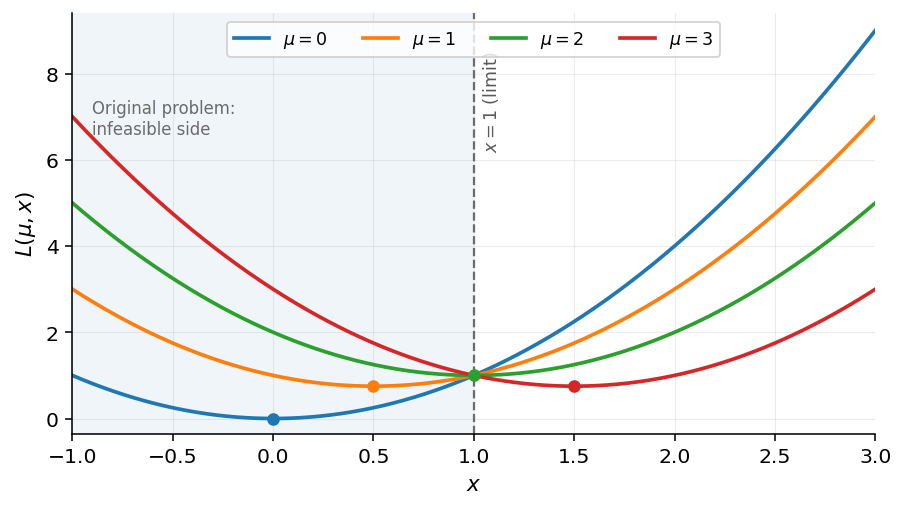

In [3]:
# Figure 1: four Lagrangian curves and unconstrained minimizers
x = np.linspace(-1,3,700)
fig,ax = plt.subplots(figsize=(7.4,3.9))
ax.axvspan(-1, 1, alpha=.065, zorder=-5)
for mu in (0,1,2,3):
    y=x*x + mu*(1-x)
    p=mu/2
    q=mu-mu*mu/4
    ax.plot(x,y,label=rf'$\mu={mu}$')
    ax.scatter([p],[q],s=30,zorder=4)
ax.axvline(1,ls='--',lw=1.15,c='0.42')
ax.text(1.035,7.35,'$x = 1$ (limit)',rotation=90,fontsize=9,color='0.35',va='center')
ax.text(-.9,7.4,'Original problem:\ninfeasible side',fontsize=8.5,color='0.42',va='top')
ax.set_xlim(-1,3);ax.set_ylim(-.35,9.4)
format_ax(ax, '$x$', r'$L(\mu, x)$')
ax.legend(frameon=True,ncol=4,loc='upper center')
fig.savefig(FIG_DIR/'01_lagrangian_minimizers.png', bbox_inches='tight', pad_inches=.15)
plt.show()

**Interpretation.** The vertex moves right by 0.5 whenever $\mu$ increases by 1. For $\mu=0$ and $1$, the Lagrangian minimizers are infeasible. At $\mu=2$, the minimizer lands on the boundary $x=1$. For $\mu=3$, it moves into the feasible side.

## 1(b) — Dual function and optimum

The dual function is the minimum of the Lagrangian over every real $x$:

$$d(\mu)=\inf_x L(\mu,x)=\mu-\frac{\mu^2}{4}
=1-\frac{(\mu-2)^2}{4},\qquad \mu\geq0.$$

We maximize this concave quadratic over $\mu\geq0$. From $d'(\mu)=1-\mu/2$, the stationary point is $\mu^*=2$. Since $d''(\mu)=-1/2<0$, it is the maximum:

$$\boxed{\mu^*=2,\quad d^*=d(2)=1}.$$

As $p^*=d^*=1$, the duality gap is zero.

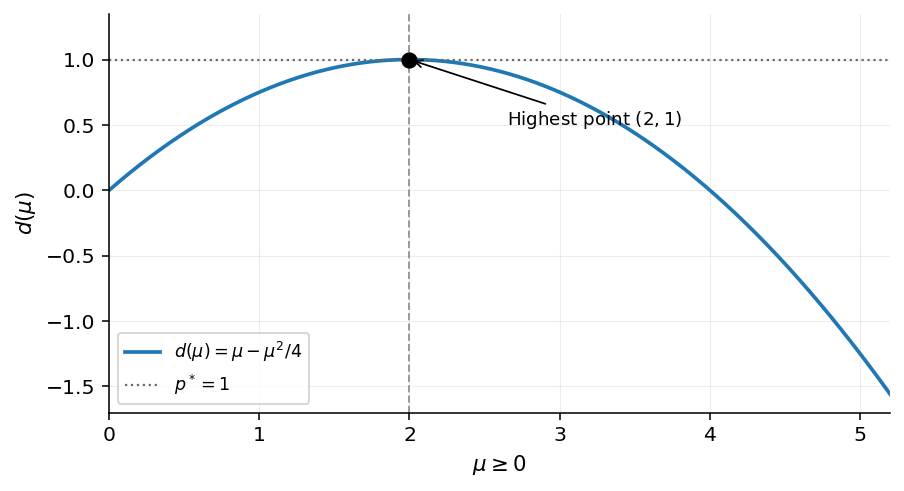

In [4]:
# Figure 2: dual function
mu=np.linspace(0,5.2,600)
d=mu-mu*mu/4
fig,ax=plt.subplots(figsize=(7.2,3.7))
ax.plot(mu,d,label=r'$d(\mu)=\mu-\mu^2/4$')
ax.axhline(1,ls=':',lw=1.15,c='0.42',label=r'$p^*=1$')
ax.axvline(2,ls='--',lw=1,c='0.6')
ax.scatter([2],[1],s=54,zorder=6,c='black')
ax.annotate(r'Highest point $(2,1)$',xy=(2,1),xytext=(2.65,.5),arrowprops=dict(arrowstyle='->',lw=.9),fontsize=9.4)
ax.set_xlim(0,5.2);ax.set_ylim(-1.7,1.35)
format_ax(ax, r'$\mu\geq 0$',r'$d(\mu)$')
ax.legend(loc='lower left')
fig.savefig(FIG_DIR/'02_dual_function.png', bbox_inches='tight', pad_inches=.15)
plt.show()

## 1(c) — Primal function and the feasibility barrier

For each fixed $x$,

$$g(x)=\sup_{\mu\geq0} L(\mu,x)=x^2+\sup_{\mu\geq0}\mu(1-x).$$

- When $x\geq1$, the coefficient $1-x\leq0$, so the largest multiplier term is zero.
- When $x<1$, the coefficient $1-x>0$. Increasing $\mu$ without limit sends the Lagrangian to $+\infty$.

Therefore,

$$\boxed{g(x)=\begin{cases} +\infty,&x<1,\\x^2,&x\geq1.\end{cases}}$$

A graph cannot display an infinite numerical value. To illustrate the behavior, limit $\mu$ temporarily to $[0,M]$:

$$g_M(x)=\max_{0\leq\mu\leq M}L(\mu,x)=x^2+M\max(1-x,0).$$

The following curves for $M=3,8,20$ illustrate the increasing penalty on infeasible points; **they are not the exact infinite branch**.

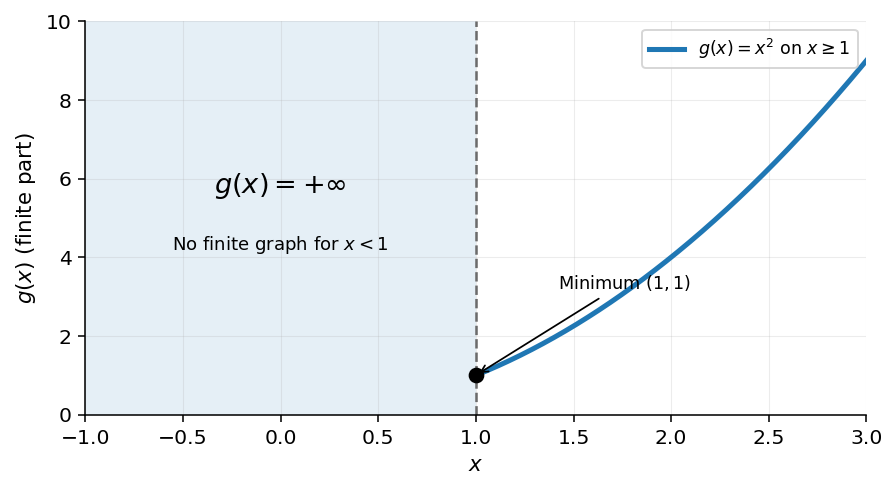

In [5]:
# Figure 3: primal function is extended-real (infinity on left)
fig,ax=plt.subplots(figsize=(7.2,3.65))
ax.axvspan(-1,1,alpha=.115,zorder=-5)
xx=np.linspace(1,3,350)
ax.plot(xx,xx**2,lw=2.6,label=r'$g(x)=x^2$ on $x\geq 1$')
ax.axvline(1,ls='--',lw=1.3,c='0.42')
ax.scatter([1],[1],s=50,c='black',zorder=5)
ax.text(0,5.65,r'$g(x)=+\infty$',ha='center',fontsize=14,weight='bold')
ax.text(0,4.2,r'No finite graph for $x<1$',ha='center',fontsize=9.3)
ax.annotate('Minimum $(1,1)$',xy=(1,1),xytext=(1.42,3.2),arrowprops=dict(arrowstyle='->',lw=.9),fontsize=9.1)
ax.set_xlim(-1,3);ax.set_ylim(0,10)
format_ax(ax,'$x$',r'$g(x)$ (finite part)')
ax.legend(loc='upper right')
fig.savefig(FIG_DIR/'03_primal_function.png', bbox_inches='tight', pad_inches=.15)
plt.show()

**Conclusion.** The function $g(x)$ assigns the original objective $x^2$ to feasible points and $+\infty$ to infeasible points. Hence minimizing $g$ over all real $x$ is equivalent to minimizing $x^2$ under $x\geq1$:

$$\boxed{\min_{x\in\mathbb R}g(x)=\min_{x\geq1}x^2=1,\qquad x^*=1.}$$